# TDE 01 — Análise Exploratória de Dados
# Predição de Salário Anual

**Etapa:** Fase 1 — Análise Exploratória de Dados (EDA)
**Dataset:** [Salary Prediction Classification ](https://www.kaggle.com/datasets/ayessa/salary-prediction-classification)

---


## 1. Contextualização

**Qual é o problema estudado?**
O estudo dos salários ao redor do mundo é fundamental para entender as relações sociais que regem a vida de diferentes populações. Este projeto investiga quais fatores (idade, escolaridade, ocupação, jornada de trabalho, estado civil, entre outros) estão associados a uma pessoa ganhar mais ou menos de 50 mil dólares por ano.

**Qual é o objetivo da análise?**
Realizar uma Análise Exploratória de Dados (EDA) sobre o dataset de predição salarial: investigar a qualidade dos dados, o comportamento individual das variáveis e as relações entre elas, preparando o terreno para a etapa posterior de classificação binária (`<=50K` vs `>50K`), cuja métrica principal será a Acurácia Balanceada.

**De onde vêm os dados?**
O dataset foi obtido do Kaggle (link acima) e corresponde a uma versão do clássico *Adult / Census Income Dataset* do UCI Machine Learning Repository, derivado do censo dos EUA de 1994.

**O que representa cada observação?**
Cada linha representa um indivíduo, descrito por características demográficas, educacionais e profissionais.

**Quais são as principais variáveis?**

| Variável | Tipo | Descrição |
|---|---|---|
| age | numérica | idade do indivíduo |
| workclass | categórica | tipo de vínculo empregatício |
| fnlwgt | numérica | peso amostral (representatividade estatística do registro na população) |
| education | categórica | grau de escolaridade |
| educational-num | numérica ordinal | escolaridade codificada em número de anos de estudo |
| marital-status | categórica | estado civil |
| occupation | categórica | ocupação profissional |
| relationship | categórica | papel familiar |
| race | categórica | etnia |
| gender | categórica | gênero |
| capital-gain | numérica | ganho de capital no ano |
| capital-loss | numérica | perda de capital no ano |
| hours-per-week | numérica | horas trabalhadas por semana |
| native-country | categórica | país de origem |
| **income** | categórica (alvo) | `<=50K` ou `>50K` |


#2. Configuração do Ambiente

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_rows', 10)
pd.set_option('display.width', 120)
sns.set_theme(style="whitegrid")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

caminho_csv = '/content/drive/MyDrive/TDE1-IA/salary.csv'

df = pd.read_csv(caminho_csv)

df.columns = ['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
              'marital-status', 'occupation', 'relationship', 'race', 'gender',
              'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
              'income']

df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# 3. Conhecimento inicial dos dados

In [ ]:
print(f"Número de linhas: {df.shape[0]}")
print(f"Número de colunas: {df.shape[1]}")
df.info()

Número de linhas: 32561
Número de colunas: 15
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              32561 non-null  int64 
 1   workclass        32561 non-null  object
 2   fnlwgt           32561 non-null  int64 
 3   education        32561 non-null  object
 4   educational-num  32561 non-null  int64 
 5   marital-status   32561 non-null  object
 6   occupation       32561 non-null  object
 7   relationship     32561 non-null  object
 8   race             32561 non-null  object
 9   gender           32561 non-null  object
 10  capital-gain     32561 non-null  int64 
 11  capital-loss     32561 non-null  int64 
 12  hours-per-week   32561 non-null  int64 
 13  native-country   32561 non-null  object
 14  income           32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [ ]:
num_cols = ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
cat_cols = ['workclass', 'education', 'marital-status', 'occupation', 'relationship',
            'race', 'gender', 'native-country', 'income']

print("Variáveis numéricas:", num_cols)
print("Variáveis categóricas:", cat_cols)

df[num_cols].describe().T

Variáveis numéricas: ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Variáveis categóricas: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country', 'income']


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
educational-num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital-gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital-loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours-per-week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [ ]:
cat_summary = pd.DataFrame({
    "n_categorias": df[cat_cols].nunique(),
    "categoria_mais_frequente": df[cat_cols].mode().iloc[0],
})
cat_summary

,n_categorias,categoria_mais_frequente
workclass,9,Private
education,16,HS-grad
marital-status,7,Married-civ-spouse
occupation,15,Prof-specialty
relationship,6,Husband
race,5,White
gender,2,Male
native-country,42,United-States
income,2,<=50K


 Observações iniciais: o dataset possui 32.561 linhas e 15 colunas, sendo 6 numéricas e 9 categóricas (incluindo o alvo income). Não há variáveis temporais. native-country é a categórica com maior cardinalidade (mais de 40 países), enquanto a maioria dos indivíduos é dos Estados Unidos, do sexo masculino e trabalha no setor privado (workclass).

#4. Qualidade dos dados

In [ ]:
n_dup = df.duplicated().sum()
print(f"Linhas duplicadas: {n_dup} ({n_dup/len(df)*100:.2f}%)")

# Valores ausentes "clássicos" (NaN)
print("\nValores nulos (NaN) por coluna:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Linhas duplicadas: 24 (0.07%)

Valores nulos (NaN) por coluna:
Series([], dtype: int64)


O dataset não apresenta valores NaN explícitos, mas isso não significa ausência de dados faltantes: no dataset Adult/Census é comum que valores desconhecidos sejam codificados como "?". Vamos investigar isso.

In [ ]:
obj_cols = df.select_dtypes(include="object").columns
mask_interrogacao = pd.DataFrame({c: (df[c].astype(str).str.strip() == "?") for c in obj_cols})
missing_como_interrogacao = mask_interrogacao.sum()
missing_como_interrogacao = missing_como_interrogacao[missing_como_interrogacao > 0]
print("Valores '?' (ausentes mascarados) por coluna:")
print(missing_como_interrogacao)
print(f"\nPercentual sobre o total de linhas:")
print((missing_como_interrogacao / len(df) * 100).round(2))


Valores '?' (ausentes mascarados) por coluna:
workclass         1836
occupation        1843
native-country     583
dtype: int64

Percentual sobre o total de linhas:
workclass         5.64
occupation        5.66
native-country    1.79
dtype: float64


In [ ]:
df = df.replace("?", np.nan)

linhas_com_algum_ausente = df.isnull().any(axis=1).sum()
print(f"Linhas com pelo menos um valor ausente: {linhas_com_algum_ausente} ({linhas_com_algum_ausente/len(df)*100:.2f}%)")

Linhas com pelo menos um valor ausente: 0 (0.00%)


In [ ]:
print("age:", df['age'].min(), "-", df['age'].max())
print("hours-per-week:", df['hours-per-week'].min(), "-", df['hours-per-week'].max())
print("educational-num:", df['educational-num'].min(), "-", df['educational-num'].max())
print("capital-gain:", df['capital-gain'].min(), "-", df['capital-gain'].max())
print("capital-loss:", df['capital-loss'].min(), "-", df['capital-loss'].max())

print("\n% de capital-gain igual a zero:", round((df['capital-gain']==0).mean()*100, 2), "%")
print("% de capital-loss igual a zero:", round((df['capital-loss']==0).mean()*100, 2), "%")
print("Pessoas com 90 anos (valor no limite superior):", (df['age']==90).sum())


age: 17 - 90
hours-per-week: 1 - 99
educational-num: 1 - 16
capital-gain: 0 - 99999
capital-loss: 0 - 4356

% de capital-gain igual a zero: 91.67 %
% de capital-loss igual a zero: 95.33 %
Pessoas com 90 anos (valor no limite superior): 43


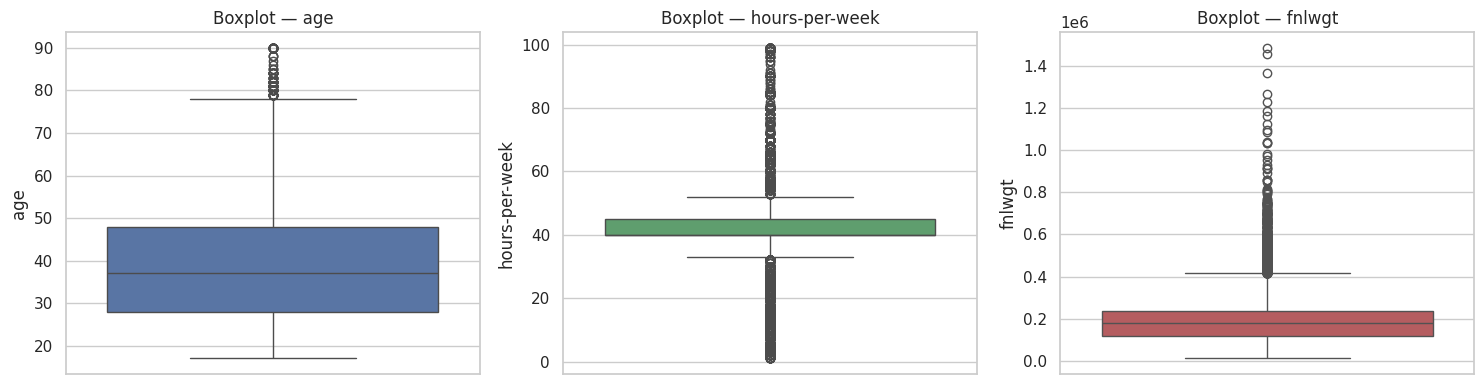

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df['age'], ax=axes[0], color="#4C72B0")
axes[0].set_title("Boxplot — age")
sns.boxplot(y=df['hours-per-week'], ax=axes[1], color="#55A868")
axes[1].set_title("Boxplot — hours-per-week")
sns.boxplot(y=df['fnlwgt'], ax=axes[2], color="#C44E52")
axes[2].set_title("Boxplot — fnlwgt")
plt.tight_layout()
plt.show()


**Decisões de tratamento e justificativas:**

- **Duplicadas (24 linhas, ~0,07%):** volume irrelevante frente ao tamanho do dataset; serão removidas na etapa de modelagem, sem impacto perceptível nas conclusões da EDA.
- **Valores `"?"` em `workclass` (5,64%), `occupation` (5,66%) e `native-country` (1,79%):** foram convertidos para `NaN` para serem tratados como ausentes de fato, em vez de uma categoria válida. Como o percentual é baixo e as três colunas raramente faltam ao mesmo tempo na mesma linha, a estratégia recomendada para a modelagem é imputação pela moda (categoria mais frequente) ou criação de uma categoria explícita `"Desconhecido"` — não removeremos essas linhas na EDA para não perder informação das demais variáveis.
- **`capital-gain` e `capital-loss` são fortemente concentrados em zero** (91,7% e 95,3% das observações, respectivamente). Isso não é um erro: reflete o fato de que a maioria das pessoas simplesmente não teve ganhos/perdas de capital naquele ano. Os valores não-zero, porém, são bem distantes da média (ex.: valores como 99.999), o que gera altíssima assimetria — tratado com atenção na análise univariada.
- **`age` limitado a 90 anos:** não é um erro de digitação, e sim uma decisão de coleta do censo original, que agrupa/limita (*top-coding*) idades muito altas em 90 para preservar anonimato. Não há valores negativos ou impossíveis (ex.: idade 0 ou 200).
- **`fnlwgt`** possui outliers segundo o boxplot, mas isso é esperado: é um peso amostral do censo (não uma característica pessoal), então não representa um "erro" — apenas indica subgrupos populacionais mais raros ou mais comuns. Essa variável tende a ter baixo poder preditivo para o problema de classificação e pode ser candidata a exclusão na modelagem.

# 5. Análise univariada

## 5.1 Variáveis numéricas

In [ ]:
df[num_cols].agg(['mean', 'median', 'std', 'min', 'max']).T.round(2)

,mean,median,std,min,max
age,38.58,37.0,13.64,17.0,90.0
fnlwgt,189778.37,178356.0,105549.98,12285.0,1484705.0
educational-num,10.08,10.0,2.57,1.0,16.0
capital-gain,1077.65,0.0,7385.29,0.0,99999.0
capital-loss,87.30,0.0,402.96,0.0,4356.0
hours-per-week,40.44,40.0,12.35,1.0,99.0


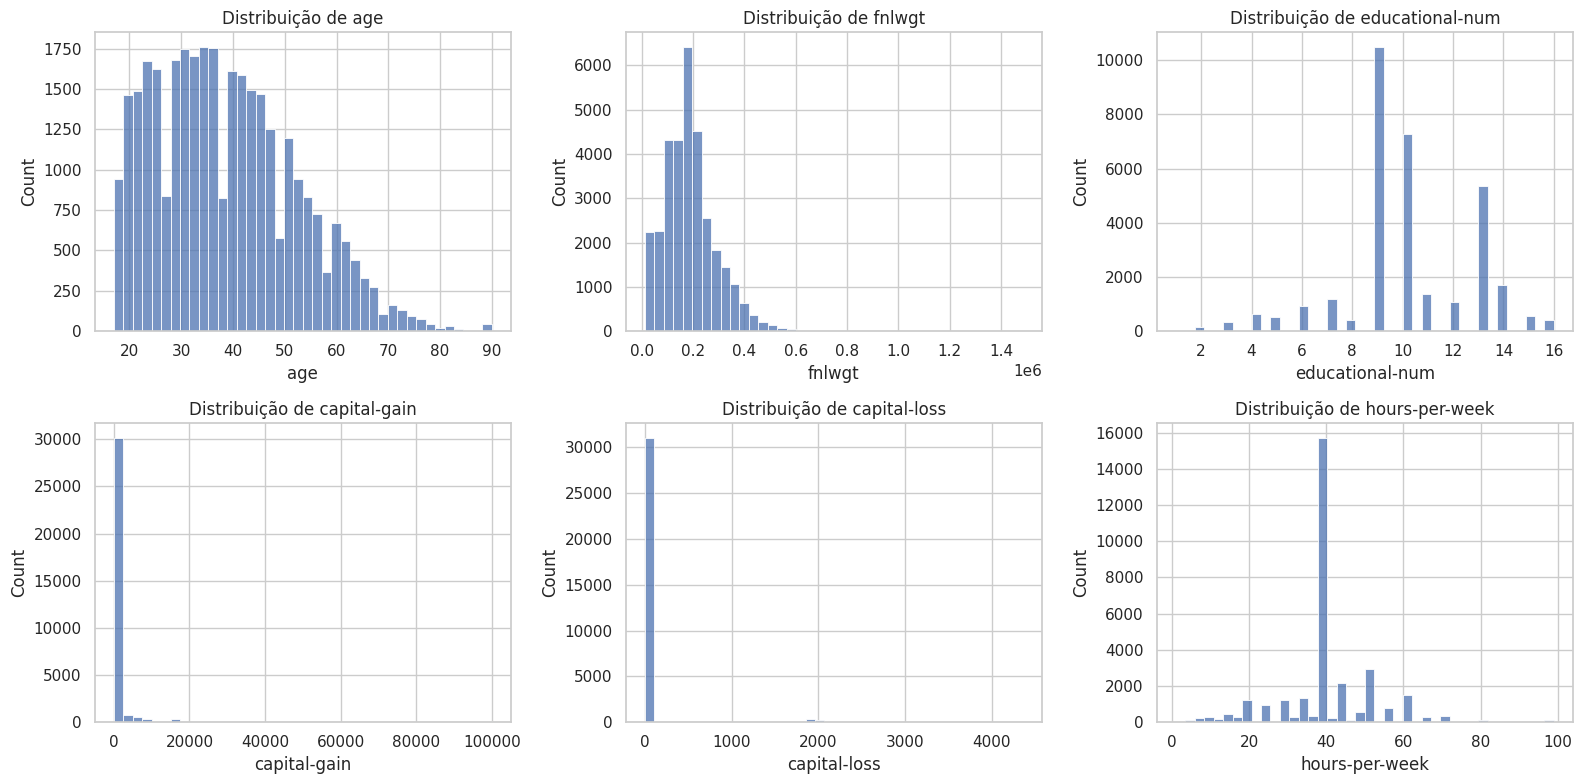

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=40, ax=ax, color="#4C72B0", kde=False)
    ax.set_title(f"Distribuição de {col}")
plt.tight_layout()
plt.show()

In [ ]:
skew = df[num_cols].skew().sort_values(ascending=False)
print("Assimetria (skewness) de cada variável numérica:")
print(skew.round(2))

Assimetria (skewness) de cada variável numérica:
capital-gain       11.95
capital-loss        4.59
fnlwgt              1.45
age                 0.56
hours-per-week      0.23
educational-num    -0.31
dtype: float64


**Interpretação:**
- **age** tem média ≈ 38,6 anos e mediana 37, com leve assimetria positiva (0,56): a população é majoritariamente adulta jovem/meia-idade, com uma cauda de indivíduos mais velhos (até o limite de 90 anos, discutido acima).
- **hours-per-week** se concentra fortemente em torno de 40 horas (jornada padrão nos EUA): cerca de 46,7% dos registros têm exatamente 40 horas semanais, o que explica a baixa assimetria (0,23) apesar de existirem extremos de 1 a 99 horas.
- **capital-gain** (assimetria ≈ 11,95) e **capital-loss** (assimetria ≈ 4,59) são extremamente assimétricas — a grande maioria dos valores é zero, e uma pequena fração da população concentra valores muito altos. Isso é típico de variáveis financeiras e sugere que, na modelagem, pode ser útil transformar essas variáveis (ex. binarizar em "teve ganho/perda" ou aplicar log) em vez de usá-las em escala bruta.
- **fnlwgt** também é bastante assimétrica (1,45), mas por ser um peso amostral e não uma característica pessoal do indivíduo, sua distribuição não é interpretada da mesma forma que as demais — reflete a distribuição de subgrupos representados na amostra do censo.
- **educational-num** tem leve assimetria negativa (-0,31): a maioria da população tem entre 9 e 13 anos de estudo (ensino médio completo até graduação), com uma cauda menor de pessoas com pouca escolaridade.

### 5.2 Variáveis categóricas

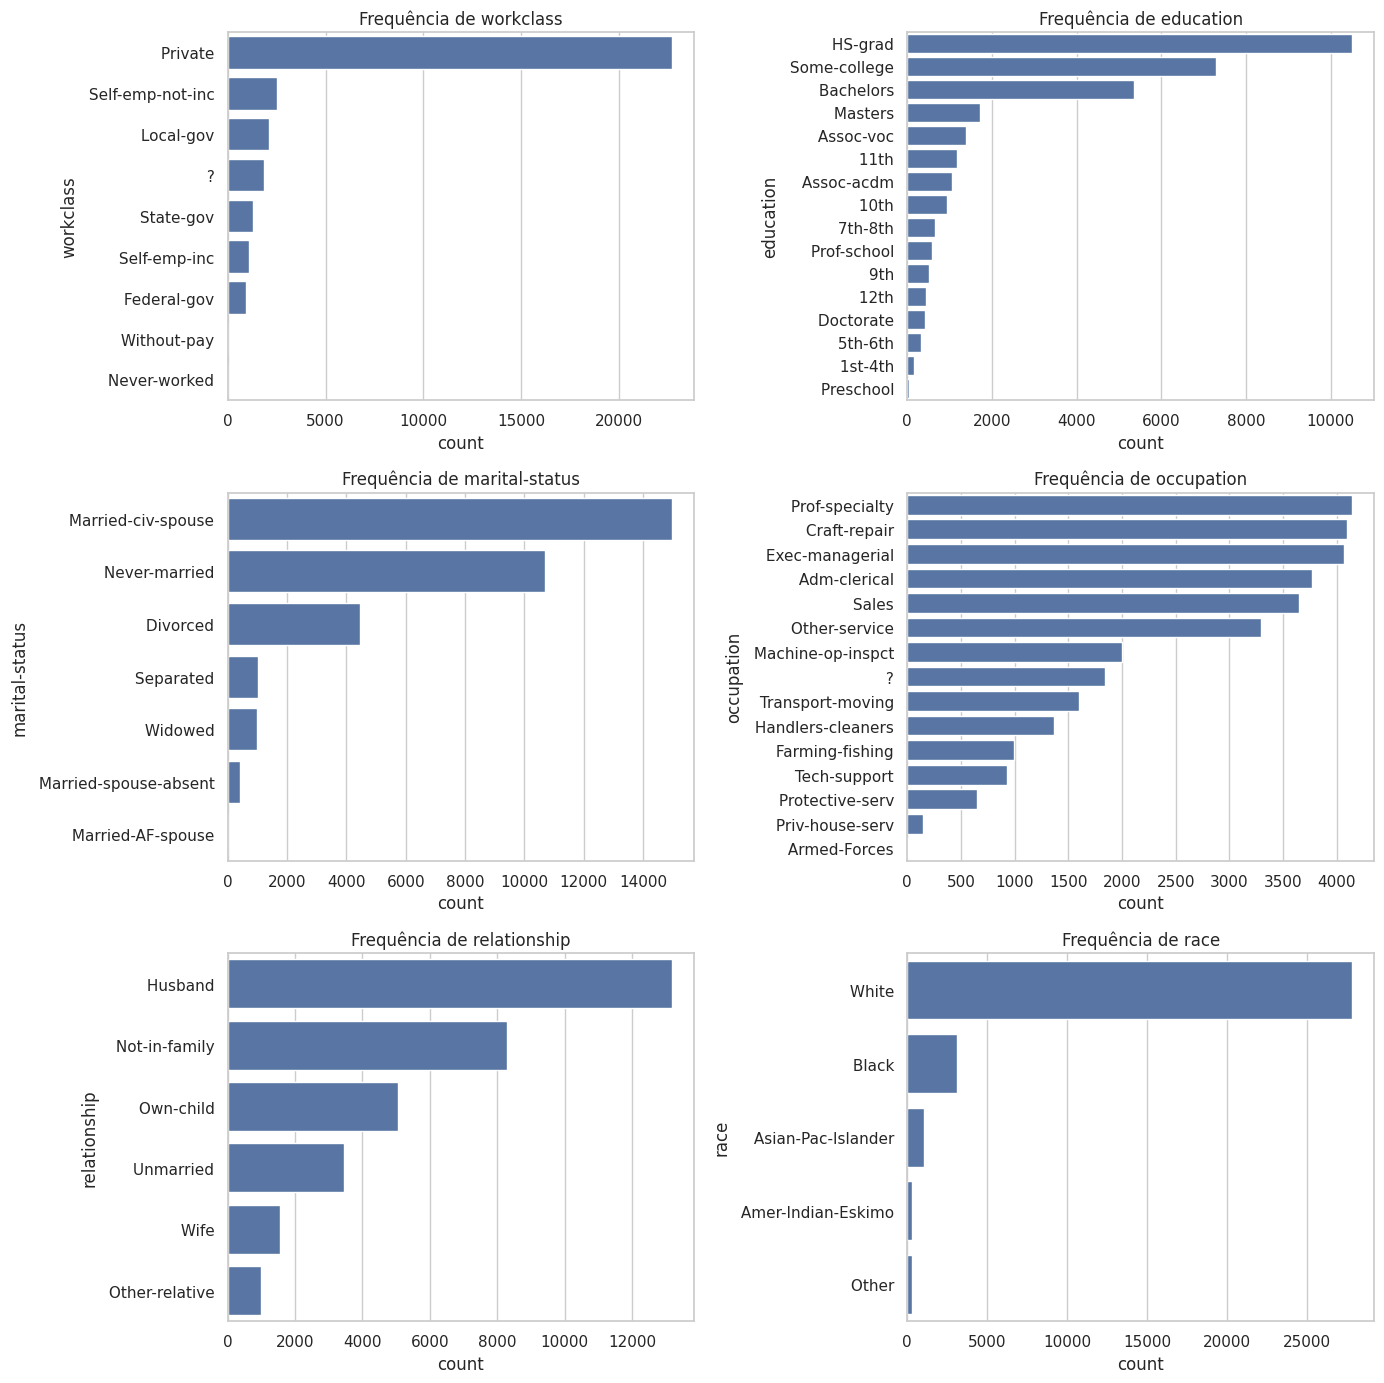

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()
plot_cats = ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race']
for ax, col in zip(axes, plot_cats):
    order = df[col].value_counts().index
    sns.countplot(y=df[col], order=order, ax=ax, color="#4C72B0")
    ax.set_title(f"Frequência de {col}")
plt.tight_layout()
plt.show()

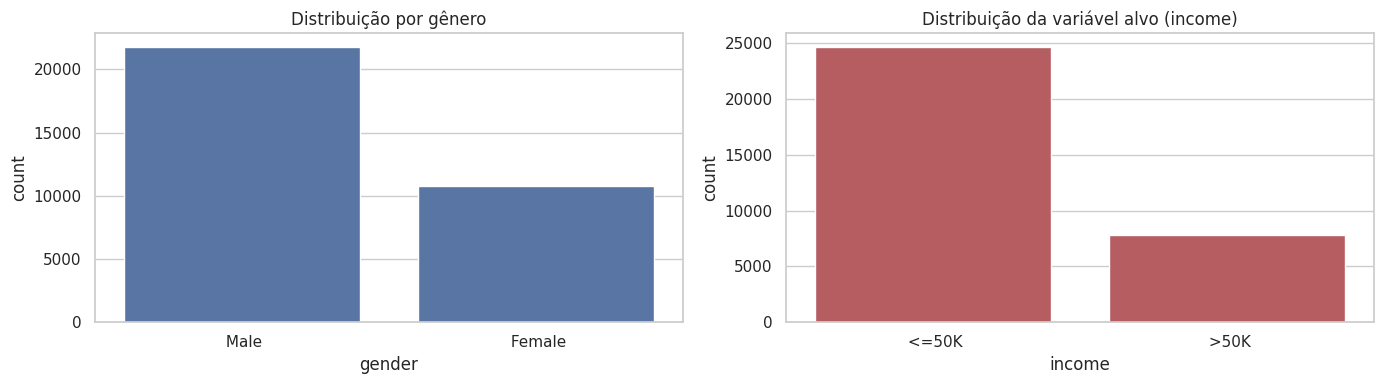

gender
Male      66.92
Female    33.08
Name: proportion, dtype: float64

income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x=df['gender'], ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribuição por gênero")
sns.countplot(x=df['income'], ax=axes[1], color="#C44E52")
axes[1].set_title("Distribuição da variável alvo (income)")
plt.tight_layout()
plt.show()

print(df['gender'].value_counts(normalize=True).mul(100).round(2))
print()
print(df['income'].value_counts(normalize=True).mul(100).round(2))

In [ ]:
print("Top 10 países de origem:")
print(df['native-country'].value_counts(normalize=True).mul(100).round(2).head(10))


Top 10 países de origem:
native-country
United-States    89.59
Mexico            1.97
?                 1.79
Philippines       0.61
Germany           0.42
Canada            0.37
Puerto-Rico       0.35
El-Salvador       0.33
India             0.31
Cuba              0.29
Name: proportion, dtype: float64


**Interpretação:**
- A variável alvo **income** é desbalanceada: 75,9% dos indivíduos ganham `<=50K` e apenas 24,1% ganham `>50K`. Isso é um ponto importante para a etapa de modelagem — reforça por que a **Acurácia Balanceada** foi escolhida como métrica principal do projeto, já que a acurácia comum poderia mascarar um modelo que simplesmente "chuta" a classe majoritária.
- A amostra é predominantemente **masculina** (66,9%) e **norte-americana** (91,2% nasceram nos EUA), o que é esperado dado que o dataset é derivado do censo dos EUA — isso é uma limitação a considerar ao generalizar conclusões para outras populações.
- Em `workclass`, a maioria trabalha no setor **Private**; em `education`, os níveis mais comuns são `HS-grad`, `Some-college` e `Bachelors`; em `marital-status`, predominam `Married-civ-spouse` e `Never-married`; a **raça branca** representa 85,4% da amostra, seguida por negra (9,6%) — uma concentração que também limita a representatividade do dataset para análises sobre outros grupos étnicos.

#6. Análise Bivariada e Multivariada

###6.1 Renda vs Gênero

income  <=50K   >50K
gender              
Female  89.05  10.95
Male    69.43  30.57


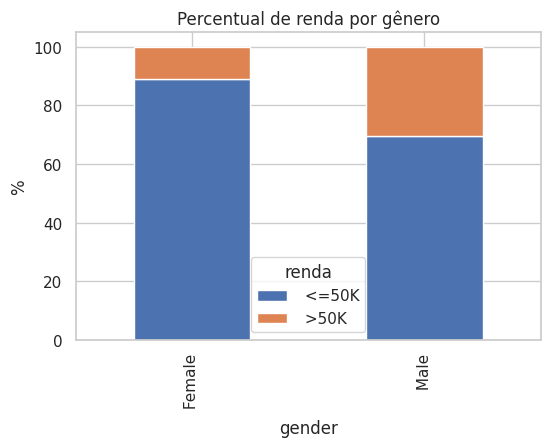

In [ ]:
tab_gender = pd.crosstab(df['gender'], df['income'], normalize='index') * 100
print(tab_gender.round(2))

tab_gender.plot(kind='bar', stacked=True, figsize=(6,4))
plt.title("Percentual de renda por gênero")
plt.ylabel("%")
plt.legend(title="renda")
plt.show()

###6.2 Renda vs Idade/Horas por Semana

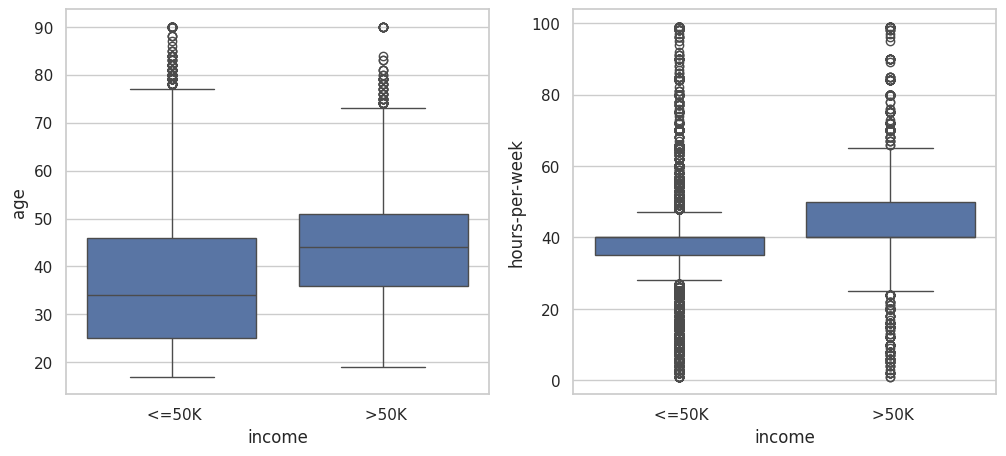

          age  hours-per-week
income                       
<=50K   36.78           38.84
>50K    44.25           45.47


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(x='income', y='age', data=df, ax=axes[0])
sns.boxplot(x='income', y='hours-per-week', data=df, ax=axes[1])
plt.show()

print(df.groupby('income')[['age', 'hours-per-week']].mean().round(2))

###6.3 Renda vs Escolaridade

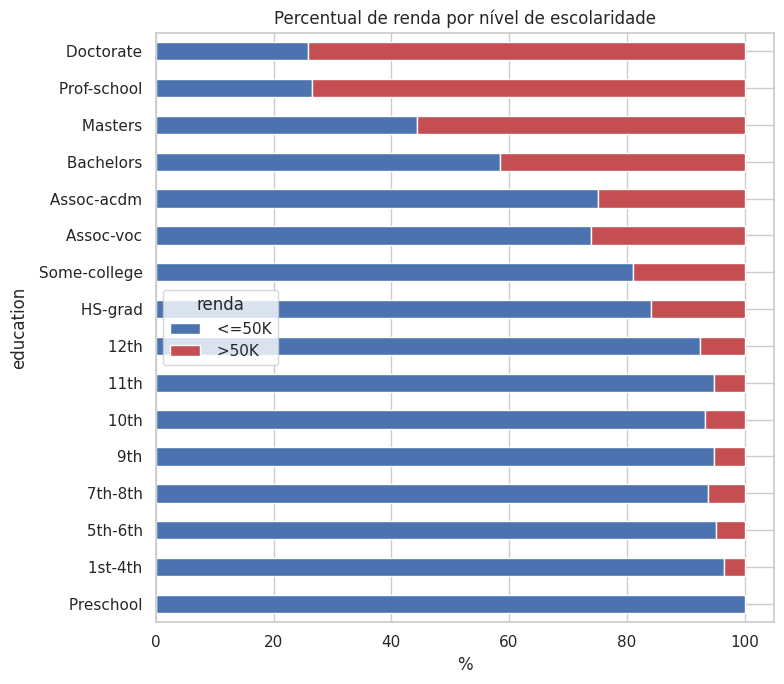

In [ ]:
edu_order = df.groupby('education')['educational-num'].mean().sort_values().index
edu_income = pd.crosstab(df['education'], df['income'], normalize='index').reindex(edu_order) * 100

edu_income.plot(kind='barh', stacked=True, figsize=(8,7), color=["#4C72B0", "#C44E52"])
plt.title("Percentual de renda por nível de escolaridade")
plt.xlabel("%")
plt.legend(title="renda")
plt.tight_layout()
plt.show()

###6.4 MUltivariada Gráfico Renda em Idade x Horas

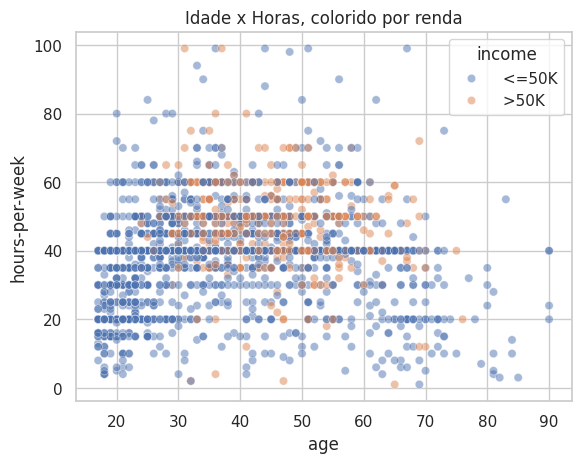

In [ ]:
sample = df.sample(3000, random_state=42)
sns.scatterplot(data=sample, x='age', y='hours-per-week', hue='income', alpha=0.5)
plt.title("Idade x Horas, colorido por renda")
plt.show()

**Interpretação:**
- **Gênero:** homens têm renda maior que 50k em 30,6% dos casos, contra apenas 10,9% das mulheres, uma disparidade relevante.
- **Escolaridade:** existe uma relação paralela entre escolaridade e renda: `Preschool` tem 0% de indivíduos acima de 50K, enquanto `Doctorate` (74,1%) e `Prof-school` (73,4%) têm as maiores taxas. Isso é o padrão mais forte identificado na EDA.
- **Estado civil:** pessoas casadas (`Married-civ-spouse`, 44,7%) têm taxa de renda alta muito superior às demais categorias (`Never-married`, apenas 4,6%) — mas isso provavelmente é confundido com idade (pessoas casadas tendem a ser mais velhas e mais estabelecidas na carreira) e não deve ser interpretado como relação causal direta.
- **Ocupação:** cargos de gestão e especialização técnica (`Exec-managerial`, 48,4%; `Prof-specialty`, 44,9%) concentram as maiores taxas de renda alta, enquanto `Other-service` (4,2%) e `Priv-house-serv` (0,7%) têm as menores.
- **Idade e horas trabalhadas:** quem ganha mais de 50k é, em média, mais velho (44,2 vs. 36,8 anos) e trabalha mais horas por semana (45,5 vs. 38,8h). Isso sugere que experiência/tempo de carreira e dedicação horária estão associados a maior renda.

#7. Identificação de Padrões, tendências e anomalias.

In [ ]:
# Concentração em torno da jornada padrão de 40h
pct_40h = (df['hours-per-week'] == 40).mean() * 100
print(f"% de pessoas trabalhando exatamente 40h/semana: {pct_40h:.2f}%")

# Limite de idade
pct_90 = (df['age'] == 90).mean() * 100
print(f"% de pessoas com idade registrada como 90 (limite superior): {pct_90:.2f}%")

# Dispersão de ganho de capital / perda de capital
print(f"% com ganho de capital = 0: {(df['capital-gain']==0).mean()*100:.2f}%")
print(f"% com perda de capital = 0: {(df['capital-loss']==0).mean()*100:.2f}%")

# valor de ganho de capital que se destaca (possível limite)
print("\nValores de ganho de capital acima de 90.000 e sua frequência:")
print(df.loc[df['capital-gain'] > 90000, 'capital-gain'].value_counts())

% de pessoas trabalhando exatamente 40h/semana: 46.73%
% de pessoas com idade registrada como 90 (limite superior): 0.13%
% com ganho de capital = 0: 91.67%
% com perda de capital = 0: 95.33%

Valores de ganho de capital acima de 90.000 e sua frequência:
capital-gain
99999    159
Name: count, dtype: int64


**Padrões e anomalias identificados:**

1. **Pico artificial em `hours-per-week = 40`** (46,7% dos registros): reflete a jornada de trabalho padrão americana, não um erro de coleta — é um comportamento social/estrutural, não um outlier estatístico.
2. **Teto da idade em 90 anos:** decisão metodológica do censo original para preservar anonimato/agrupar extremos, e não um erro de digitação.
3. **`ganho de capital` apresenta um valor isolado e recorrente em 99.999**, muito acima do restante da distribuição — um padrão clássico de *top-coding* também nessa variável (valores muito altos são "cortados" em um teto fixo pelo órgão que coletou os dados).
4. **Desbalanceamento da variável alvo** (76% vs. 24%) é o padrão estrutural mais importante do dataset para a próxima fase do projeto, pois direciona a escolha de métrica na modelagem.
5. **Diferença de renda por gênero e por estado civil** aparecem como os padrões de maior magnitude entre as variáveis categóricas, superando inclusive algumas diferenças entre grupos ocupacionais.
6. Não foram encontrados **valores impossíveis** (idade negativa, horas negativas, categorias inconsistentes).

## 8. Insights

**Quais padrões foram encontrados?**
Escolaridade, ocupação e estado civil são os fatores categóricos mais fortemente associados à renda. Idade e horas trabalhadas por semana também têm relação positiva com renda alta.

**Existem comportamentos inesperados?**
A concentração extrema de `ganho de capital` e `perda de capital` em zero, com um valor de "teto" isolado (99.999), é um comportamento que exige tratamento especial e não deveria ser usado ingenuamente como variável contínua em um modelo linear.

**Existem grupos com comportamentos diferentes?**
Sim, a disparidade de renda entre gêneros (30,6% dos homens vs. 10,9% das mulheres acima de 50K) e entre grupos ocupacionais (de 0,7% em `Priv-house-serv` a 48,4% em `Exec-managerial`) são as diferenças mais marcantes.

**Existem valores atípicos relevantes?**
Os principais "outliers" identificados são, em sua maioria, resultado de decisões metodológicas de coleta do censo, não erros por isso não devem ser simplesmente removidos, mas tratados com conhecimento de contexto.

**Quais relações parecem importantes?**
`education` / `educational-num`, `occupation`, `marital-status`, `hours-per-week` e `age` em relação a `income`. Já `fnlwgt`, por definição, não deve ser usada como variável preditiva de renda individual.

**Quais hipóteses podem ser levantadas a partir da análise?**
- H1: Escolaridade é o preditor individual mais forte de renda alta.
- H2: O efeito do estado civil sobre a renda é parcialmente explicado pela idade, e não puramente causal.
- H3: A disparidade de renda por gênero persiste mesmo controlando por ocupação.

## 9. Conclusão

**Principais descobertas:**
O dataset está em boas condições estruturais, sem valores impossíveis, e ausência mascarada concentrada em apenas três colunas categóricas (`workclass`, `occupation`, `native-country`, entre 1,8% e 5,7% cada). A variável alvo `income` é desbalanceada (76% `<=50K` / 24% `>50K`), o que já direciona decisões da fase de modelagem.

**Principais insights obtidos:**
Escolaridade, ocupação e estado civil emergem como os fatores mais associados à renda alta, seguidos por idade e horas trabalhadas. Gênero apresenta disparidade relevante que merece investigação causal mais cuidadosa.

**Limitações dos dados:**
- Amostra fortemente concentrada nos EUA e na raça branca, limitando a generalização das conclusões para outras populações e países.
- Dataset derivado do censo de 1994, padrões salariais e sociais (ex. participação feminina no mercado de trabalho, distribuição ocupacional) podem não refletir a realidade atual.

**Questões que permaneceram em aberto:**
- A disparidade de renda por gênero se mantém ao controlar por ocupação e horas trabalhadas, ou é majoritariamente explicada por essas variáveis?
- Qual o efeito real de `native-country` sobre a renda, considerando o forte desbalanceamento entre países?
- Interações entre `education` e `occupation`: será que a mesma escolaridade leva a rendas muito diferentes dependendo da ocupação escolhida?

**Possíveis próximos passos para o projeto:**
1. Tratar os valores ausentes mascarados (`"?"`) com imputação pela moda ou categoria explícita `"Desconhecido"`.
2. Treinar modelos de classificação binária, com validação cuidadosa do desbalanceamento de classes e avaliação pela Acurácia Balanceada.
3. Investigar interações multivariadas (gênero × ocupação, educação × ocupação) para testar as hipóteses levantadas nesta EDA.